In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("Iris.csv")

In [3]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
data.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [5]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
data.shape

(150, 5)

In [8]:
data.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [9]:
data.columns = data.columns.str.strip().str.lower()
data["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [10]:
data = data.drop(columns=["id"], errors="ignore")

In [11]:
data.corr(numeric_only=True)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.117570,0.871754,0.817941
sepal_width,-0.117570,1.000000,-0.428440,-0.366126
petal_length,0.871754,-0.428440,1.000000,0.962865
petal_width,0.817941,-0.366126,0.962865,1.000000


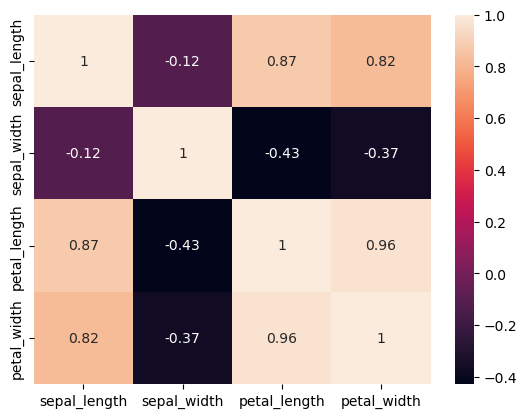

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

In [13]:
x = data.drop("species", axis=1)
y = data["species"]

In [14]:
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [15]:
y

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: object

In [16]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [17]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [18]:
encoder.classes_

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [20]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2,
    random_state=42, stratify=y_train
)

In [22]:
X_train.shape, X_val.shape, X_test.shape

((76, 4), (20, 4), (30, 4))

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [24]:
X_train

array([[-0.12912447, -1.17623746,  0.71137507,  1.1067357 ],
       [ 0.32731552, -0.48326035,  0.54364651,  0.03864791],
       [ 0.78375551, -0.48326035,  0.48773699,  0.43918083],
       [ 1.5825255 ,  0.44070913,  1.27047026,  0.83971375],
       [-0.81378446,  0.6717015 , -1.13363907, -0.8959289 ],
       [-0.12912447, -0.25226798,  0.26409891,  0.17215889],
       [-0.58556446,  1.59567097, -1.24545811, -1.29646182],
       [ 1.01197551, -1.17623746,  1.15865122,  0.83971375],
       [-1.15611445, -0.02127561, -1.30136763, -1.42997279],
       [ 0.32731552, -0.48326035,  0.15227987,  0.17215889],
       [-0.81378446,  1.82666334, -1.18954859, -1.29646182],
       [ 2.03896549, -0.02127561,  1.60592738,  1.24024667],
       [-0.69967446,  1.13368623, -1.24545811, -1.29646182],
       [ 0.09909552, -0.02127561,  0.76728459,  0.83971375],
       [-1.04200446,  1.3646786 , -1.30136763, -1.42997279],
       [-0.81378446, -1.17623746, -0.40681532, -0.09486306],
       [-1.72666444, -0.

In [25]:
import tensorflow as tf

tf.random.set_seed(42)

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [27]:
model = Sequential()

model.add(Input(shape=(4,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(4, activation="relu"))
model.add(Dense(3, activation="softmax"))

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91 (364.00 B)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val)
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7632 - loss: 0.9303 - val_accuracy: 0.8000 - val_loss: 0.9271
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7632 - loss: 0.9118 - val_accuracy: 0.8000 - val_loss: 0.9110
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7500 - loss: 0.8941 - val_accuracy: 0.8000 - val_loss: 0.8952
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7500 - loss: 0.8768 - val_accuracy: 0.8000 - val_loss: 0.8794
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7368 - loss: 0.8596 - val_accuracy: 0.8500 - val_loss: 0.8629
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7368 - loss: 0.8427 - val_accuracy: 0.8000 - val_loss: 0.8466
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7500 - loss: 0.8261 - val_accuracy: 0.8000 - val_loss: 0.8308
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7632 - loss: 0.8099 - val_accuracy: 0.8000 - val_loss: 0.8153

In [31]:
pd.DataFrame(history.history)

,accuracy,loss,val_accuracy,val_loss
0,0.763158,0.930300,0.80,0.927105
1,0.763158,0.911792,0.80,0.910981
2,0.750000,0.894085,0.80,0.895231
3,0.750000,0.876752,0.80,0.879435
4,0.736842,0.859631,0.85,0.862893
...,...,...,...,...
95,0.868421,0.314757,0.90,0.288630
96,0.868421,0.312744,0.90,0.286563
97,0.868421,0.310755,0.90,0.284512
98,0.868421,0.308785,0.90,0.282437


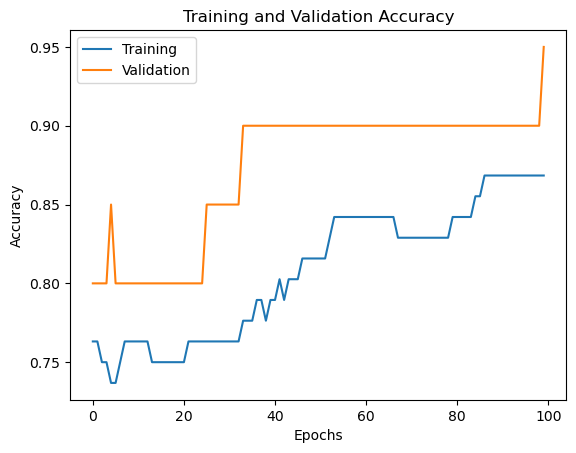

In [32]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

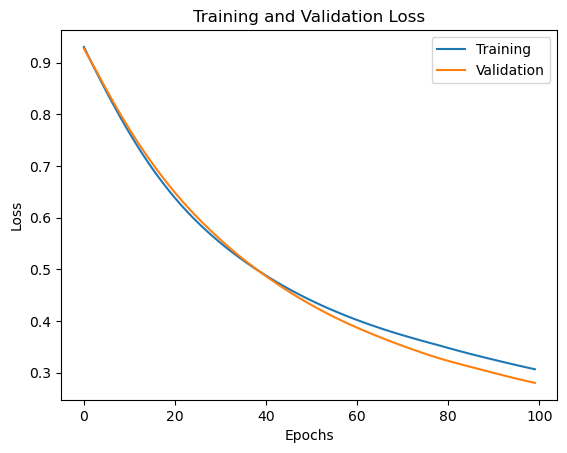

In [33]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [34]:
tr_predicted = model.predict(X_train)
tr_predicted

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


array([[1.06652072e-02, 5.04601121e-01, 4.84733671e-01],
       [3.98377962e-02, 5.22287786e-01, 4.37874377e-01],
       [2.26685945e-02, 3.94078285e-01, 5.83253145e-01],
       [2.54507200e-03, 1.11284442e-01, 8.86170387e-01],
       [9.82465744e-01, 1.51582118e-02, 2.37595756e-03],
       [7.24683255e-02, 6.03241682e-01, 3.24289918e-01],
       [9.92962718e-01, 6.26621116e-03, 7.71055231e-04],
       [3.20355804e-03, 2.02236086e-01, 7.94560432e-01],
       [9.84589458e-01, 1.36108082e-02, 1.79964374e-03],
       [5.72431497e-02, 5.92798650e-01, 3.49958211e-01],
       [9.93861377e-01, 5.48736239e-03, 6.51227543e-04],
       [5.46271331e-04, 4.66836654e-02, 9.52770054e-01],
       [9.91191864e-01, 7.79080158e-03, 1.01736432e-03],
       [2.20572185e-02, 3.26094210e-01, 6.51848674e-01],
       [9.94910002e-01, 4.57349000e-03, 5.16504806e-04],
       [1.67450145e-01, 7.07775950e-01, 1.24773912e-01],
       [9.92072821e-01, 7.19498284e-03, 7.32254703e-04],
       [3.20783891e-02, 3.77633

In [35]:
import numpy as np

tr_predicted = np.argmax(tr_predicted, axis=1)
tr_predicted

array([1, 1, 2, 2, 0, 1, 0, 2, 0, 1, 0, 2, 0, 2, 0, 1, 0, 2, 0, 0, 2, 0,
       0, 0, 1, 2, 2, 2, 2, 1, 1, 0, 2, 2, 0, 0, 1, 1, 2, 1, 1, 0, 2, 2,
       2, 1, 0, 0, 1, 2, 2, 0, 2, 1, 0, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 0,
       2, 0, 0, 0, 2, 1, 0, 2, 1, 2])

In [36]:
from sklearn.metrics import accuracy_score

accuracy_score(y_train, tr_predicted)

0.868421052631579

In [37]:
test_predicted = model.predict(X_test)
test_predicted

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


array([[9.87615883e-01, 1.11423265e-02, 1.24171353e-03],
       [2.18203273e-02, 3.24592561e-01, 6.53587162e-01],
       [8.56508687e-02, 7.81084418e-01, 1.33264735e-01],
       [6.66370913e-02, 7.99586415e-01, 1.33776471e-01],
       [9.94018555e-01, 5.35080815e-03, 6.30677096e-04],
       [3.47699113e-02, 3.57952714e-01, 6.07277393e-01],
       [9.97510314e-01, 2.27696844e-03, 2.12753876e-04],
       [9.84451473e-01, 1.34991966e-02, 2.04943027e-03],
       [8.86576716e-03, 2.08896384e-01, 7.82237828e-01],
       [6.54514655e-02, 5.75534344e-01, 3.59014302e-01],
       [1.53473229e-03, 8.27139169e-02, 9.15751278e-01],
       [4.76546539e-03, 1.45949498e-01, 8.49285007e-01],
       [3.78622185e-03, 1.34026542e-01, 8.62187266e-01],
       [3.91406640e-02, 3.86010528e-01, 5.74848831e-01],
       [9.90859210e-01, 8.07584263e-03, 1.06499263e-03],
       [9.90608811e-01, 8.29011761e-03, 1.10110315e-03],
       [9.95698571e-01, 3.88214714e-03, 4.19311284e-04],
       [5.38863987e-02, 7.50370

In [38]:
test_predicted = np.argmax(test_predicted, axis=1)
test_predicted

array([0, 2, 1, 1, 0, 2, 0, 0, 2, 1, 2, 2, 2, 2, 0, 0, 0, 1, 2, 2, 0, 2,
       2, 2, 2, 2, 2, 0, 2, 0])

In [39]:
accuracy = accuracy_score(y_test, test_predicted)
accuracy

0.8

In [40]:
loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", loss)
print("Testing Accuracy:", test_accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8000 - loss: 0.3347
Testing Loss: 0.33469581604003906
Testing Accuracy: 0.800000011920929


In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_predicted)
cm

array([[10,  0,  0],
       [ 0,  4,  6],
       [ 0,  0, 10]])

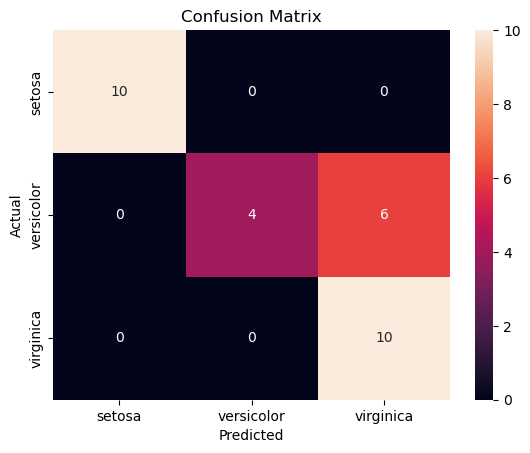

In [42]:
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [43]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, test_predicted,
    target_names=encoder.classes_,
    zero_division=0
))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.40      0.57        10
   virginica       0.62      1.00      0.77        10

    accuracy                           0.80        30
   macro avg       0.88      0.80      0.78        30
weighted avg       0.88      0.80      0.78        30



In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [45]:
precision = precision_score(
    y_test, test_predicted, average="macro", zero_division=0
)

precision

0.875

In [46]:
recall = recall_score(
    y_test, test_predicted, average="macro", zero_division=0
)

recall

0.7999999999999999

In [47]:
f1 = f1_score(
    y_test, test_predicted, average="macro", zero_division=0
)

f1

0.7802197802197802

In [48]:
performance = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

performance

,Metric,Score
0,Accuracy,0.80000
1,Precision,0.87500
2,Recall,0.80000
3,F1 Score,0.78022


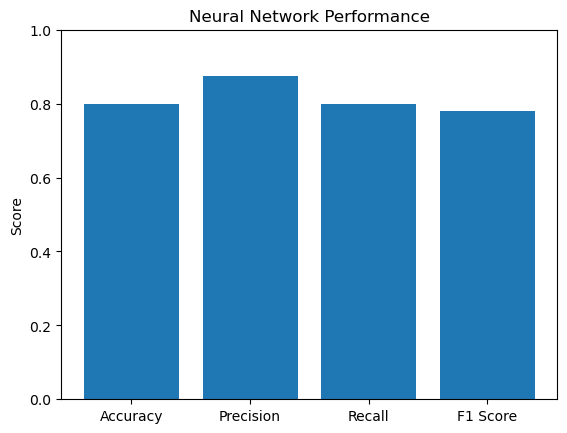

In [49]:
plt.bar(performance["Metric"], performance["Score"])

plt.ylabel("Score")
plt.title("Neural Network Performance")
plt.ylim(0, 1)
plt.show()

In [50]:
new_data = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=x.columns
)

new_data

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


In [51]:
new_data_scaled = scaler.transform(new_data)

In [52]:
prediction = model.predict(new_data_scaled)
prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


array([[9.9280256e-01, 6.4046192e-03, 7.9279614e-04]], dtype=float32)

In [53]:
predicted_class = np.argmax(prediction, axis=1)

encoder.inverse_transform(predicted_class)

array(['setosa'], dtype=object)

In [54]:
model.save("iris_model.keras")

In [55]:
import joblib

joblib.dump(scaler, "scaler.pkl")
joblib.dump(encoder, "encoder.pkl")

['encoder.pkl']

In [56]:
print("Training Accuracy:", accuracy_score(y_train, tr_predicted))
print("Testing Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Testing Loss:", loss)

Training Accuracy: 0.868421052631579
Testing Accuracy: 0.8
Precision: 0.875
Recall: 0.7999999999999999
F1 Score: 0.7802197802197802
Testing Loss: 0.33469581604003906
